# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170267          # <-- your full roll number
NAME = "Divyansh Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170130   Name: Manya Kedia   Fingerprint: AEBC2571   Tickets: 12

Ticket_ID                                                                        Ticket_Text
      T01                     I reinstalled the projector on my laptop. It worked yesterday.
      T02                                       Call me on +91 98765 43210 or 0175-239-3201.
      T03                                                 Dr. Rao's lab PC (No. 14) is down.
      T04 VPN keeps asking for login after restarting the system. I don't know what changed.
      T05                                              I need Windows 11 by 5.30 p.m. today.
      T06    Laptop has stopped syncing while uploading the file. I don't know what changed.
      T07         I cannot access the server after restarting the system. Please resolve it.
      T08                            The password failed to open. I don't know what changed.
      T09       Matlab is showing an error after restarting the system. It worke

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
processed_tickets = []

for ticket in df["Ticket_Text"]:
    result = process_ticket(ticket)
    processed_tickets.append(result)


rows = []

for i, result in enumerate(processed_tickets, start=1):

    rows.append({
        "Ticket": f"T{i:02d}",
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary_df = pd.DataFrame(rows)

total_row = {
    "Ticket": "TOTAL",
    "Sentences": summary_df["Sentences"].sum(),
    "Tokens": summary_df["Tokens"].sum(),
    "Punctuation Tokens": summary_df["Punctuation Tokens"].sum(),
    "Stopwords": summary_df["Stopwords"].sum(),
    "Unique Tokens": summary_df["Unique Tokens"].sum(),
    "Final Tokens": summary_df["Final Tokens"].sum()
}

summary_df = pd.concat(
    [summary_df, pd.DataFrame([total_row])],
    ignore_index=True
)

print(summary_df.to_string(index=False))

# Display details for the first ticket

selected = processed_tickets[0]

print("\nSELECTED TICKET:")
print(df.iloc[0]["Ticket_Text"])

print("\nACTUAL TOKENS:")
print(selected["tokens"])

print("\nPUNCTUATION TOKENS:")
print(selected["punct"])

print("\nSTOPWORDS:")
print(selected["stops"])

print("\nFINAL TOKENS:")
print(selected["final"])

Ticket  Sentences  Tokens  Punctuation Tokens  Stopwords  Unique Tokens  Final Tokens
   T01          2      12                   2          5             11             5
   T02          1       9                   1          3              9             5
   T03          2      13                   4          3             12             6
   T04          2      17                   2          6             16             9
   T05          1       9                   1          2              9             6
   T06          2      16                   2          6             15             8
   T07          2      15                   2          7             13             6
   T08          2      13                   2          5             12             6
   T09          2      14                   2          5             13             7
   T10          2      16                   2          5             15             9
   T11          1      11                   2         

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens such as n't, 's, and ca are not complete English words. They are produced by NLTK's word_tokenize() when contractions are split into separate tokens. Since these pieces are not punctuation or stopwords, they remain in the final token list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

patterns = {
    "long": r"\b[A-Za-z]{6,}\b",
    "number": r"\b\d+(?:\.\d+)*\b",
    "capital": r"\b[A-Z][A-Za-z]*\b",
    "vowel": r"\b[AEIOUaeiou][A-Za-z]*\b"
}

email = r"\b[\w.-]+@[\w.-]+\.\w+\b"
url = r"https?://\S+|www\.\S+"
phone = r"(?<!\d)\+?\d[\d\s().-]{7,}\d(?!\d)"

for line in TEST_LINES:
    print("LONG:", re.findall(patterns["long"], line))
    print("NUMBERS:", re.findall(patterns["number"], line))
    print("CAPITAL:", re.findall(patterns["capital"], line))
    print("VOWEL:", re.findall(patterns["vowel"], line))

    x = re.sub(email, "<EMAIL>", line)
    x = re.sub(url, "<URL>", x)
    x = re.sub(phone, "<PHONE>", x)

    print("REPLACED:", x)
    print()

count = 0

for line in TEST_LINES:
    words = re.findall(patterns["capital"], line)
    first = line.split()[0].strip(".,!?;:")

    if first in words:
        count += 1

print(count)

LONG: ['helpdesk', 'thapar', 'thapar', 'thapar']
NUMBERS: []
CAPITAL: ['Mail']
VOWEL: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
REPLACED: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

LONG: ['Version']
NUMBERS: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
CAPITAL: ['Call', 'Version', 'Rs']
VOWEL: ['or', 'is']
REPLACED: Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

LONG: []
NUMBERS: ['5.30']
CAPITAL: ['The']
VOWEL: ['of', 'art', 'isn', 'open', 'in', 'at']
REPLACED: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

3


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 3

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"https?://\S+|www\.\S+|[\w.-]+@[\w.-]+\.\w+|\+?\d[\d\s().-]{7,}\d|\d+(?:\.\d+)+|[A-Za-z]+(?:-[A-Za-z]+)+|[A-Za-z]+(?:'[A-Za-z]+)|[A-Za-z]+|[.,!?;:()]"

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print(my_tokenize(line))


different = 0

for ticket in df["Ticket_Text"]:
    a = word_tokenize(ticket)
    b = my_tokenize(ticket)

    if a != b:
        different += 1

print("Different tickets:", different)

for line in TEST_LINES:
    print("word_tokenize:", word_tokenize(line))
    print("my_tokenize:", my_tokenize(line))
    print()

['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', 'done', ';', 'fee', 'Rs', ',', '.']
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
Different tickets: 8
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 8


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [11]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r"(ing|ed|ly|es|s)$", min=4)
lemmatizer = WordNetLemmatizer()

words = sorted(set(
    x
    for r in processed_tickets
    for x in r["final"]
))

def get_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

data = []

for word, tag in pos_tag(words):
    data.append([
        word,
        porter.stem(word),
        lancaster.stem(word),
        regexp.stem(word),
        lemmatizer.lemmatize(word, get_pos(tag))
    ])

stem_df = pd.DataFrame(
    data,
    columns=["Word", "Porter", "Lancaster", "Regexp", "Lemma"]
)

different = stem_df[
    (stem_df.Porter != stem_df.Lancaster) |
    (stem_df.Porter != stem_df.Regexp) |
    (stem_df.Porter != stem_df.Lemma) |
    (stem_df.Lancaster != stem_df.Regexp) |
    (stem_df.Lancaster != stem_df.Lemma) |
    (stem_df.Regexp != stem_df.Lemma)
]

different

,Word,Porter,Lancaster,Regexp,Lemma
8,access,access,access,acces,access
9,another,anoth,anoth,another,another
11,call,call,cal,call,call
12,changed,chang,chang,chang,change
14,error,error,er,error,error
16,file,file,fil,file,file
18,jammed,jam,jam,jamm,jam
25,mobile,mobil,mobl,mobile,mobile
27,need,need,nee,ne,need
28,open,open,op,open,open


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*  overstemming: resolve,
understemming: tried

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1 Total: 157
S1 Unique: 92
S1 TTR: 0.5859872611464968
S3 Total: 79
S3 Unique: 57
S3 TTR: 0.7215189873417721
S4 Total: 79
S4 Unique: 57
S4 TTR: 0.7215189873417721

S1: [('.', 19), ('I', 8), ('the', 6), ("n't", 5), ('is', 3), ('after', 3), ('restarting', 3), ('system', 3), ('do', 3), ('know', 3)]
S3: [("n't", 5), ('restarting', 3), ('system', 3), ('know', 3), ('changed', 3), ('laptop', 2), ('worked', 2), ('yesterday', 2), ('keeps', 2), ('asking', 2)]


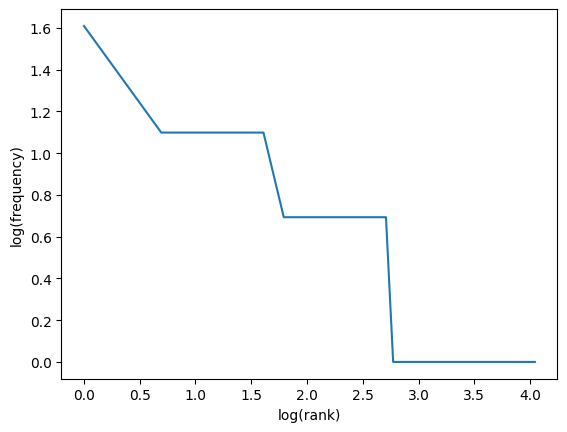

S1 Bigrams: [(('.', 'I'), 6), (('after', 'restarting'), 3), (('restarting', 'the'), 3), (('the', 'system'), 3), (('system', '.'), 3)]
S3 Bigrams: [(('restarting', 'system'), 3), (("n't", 'know'), 3), (('know', 'changed'), 3), (('worked', 'yesterday'), 2), (('keeps', 'asking'), 2)]


In [13]:
from collections import Counter
from collections import Counter
import math
import matplotlib.pyplot as plt

S1 = []
for ticket in df["Ticket_Text"]:
    S1.extend(word_tokenize(ticket))

S3 = []
for ticket in df["Ticket_Text"]:
    S3.extend(process_ticket(ticket)["final"])

stemmer = PorterStemmer()
S4 = [stemmer.stem(w) for w in S3]

print("S1 Total:", len(S1))
print("S1 Unique:", len(set(S1)))
print("S1 TTR:", len(set(S1))/len(S1))

print("S3 Total:", len(S3))
print("S3 Unique:", len(set(S3)))
print("S3 TTR:", len(set(S3))/len(S3))

print("S4 Total:", len(S4))
print("S4 Unique:", len(set(S4)))
print("S4 TTR:", len(set(S4))/len(S4))

print()
print("S1:", Counter(S1).most_common(10))
print("S3:", Counter(S3).most_common(10))

freq = Counter(S3)
x = []
y = []

for rank, count in enumerate(sorted(freq.values(), reverse=True), 1):
    x.append(math.log(rank))
    y.append(math.log(count))

plt.plot(x, y)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.show()

print("S1 Bigrams:", Counter(zip(S1, S1[1:])).most_common(5))
print("S3 Bigrams:", Counter(zip(S3, S3[1:])).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because S4 contains Porter-stemmed words. Stemming combines different word forms into common stems, which changes the number of unique tokens and therefore changes the TTR.